In [ ]:
!pip -q install torch torchvision tqdm

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np
import random

In [ ]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),  # deja en [0,1]
])

full_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_ds     = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

# split train/val (por ej 90/10)
val_frac = 0.1
n_total = len(full_train)
n_val   = int(n_total * val_frac)
n_train = n_total - n_val

train_ds, val_ds = random_split(full_train, [n_train, n_val], generator=torch.Generator().manual_seed(42))

def make_loaders(batch_size=128):
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader

train_loader, val_loader = make_loaders(batch_size=128)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 217kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.94MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 8.49MB/s]


In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, s=1, p=1, dropout=0.0):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=k, stride=s, padding=p, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()
    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = F.relu(x, inplace=True)
        x = self.drop(x)
        return x

class DeconvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, k=4, s=2, p=1, dropout=0.0):
        super().__init__()
        self.deconv = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=k, stride=s, padding=p, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()
    def forward(self, x):
        x = self.deconv(x)
        x = self.bn(x)
        x = F.relu(x, inplace=True)
        x = self.drop(x)
        return x

class DeepConvAutoencoder(nn.Module):
    def __init__(self, base_ch=32, dropout=0.1, bottleneck_ch=None):
        super().__init__()
        if bottleneck_ch is None:
            bottleneck_ch = base_ch * 4

        # Input: (B,1,28,28)
        self.enc1 = ConvBlock(1, base_ch,     k=3, s=1, p=1, dropout=dropout)  # 28x28
        self.enc2 = ConvBlock(base_ch, base_ch*2, k=4, s=2, p=1, dropout=dropout)  # 14x14
        self.enc3 = ConvBlock(base_ch*2, base_ch*4, k=4, s=2, p=1, dropout=dropout)  # 7x7
        self.bott = ConvBlock(base_ch*4, bottleneck_ch, k=3, s=1, p=1, dropout=dropout)  # 7x7

        # Decoder: 7x7 -> 14x14 -> 28x28
        self.dec1 = DeconvBlock(bottleneck_ch, base_ch*4, k=3, s=1, p=1, dropout=dropout) # 7x7
        self.dec2 = DeconvBlock(base_ch*4, base_ch*2, k=4, s=2, p=1, dropout=dropout)     # 14x14
        self.dec3 = DeconvBlock(base_ch*2, base_ch,   k=4, s=2, p=1, dropout=dropout)     # 28x28

        self.out_conv = nn.Conv2d(base_ch, 1, kernel_size=3, padding=1)
        # salida en [0,1]
        self.out_act = nn.Sigmoid()

    def forward(self, x):
        x = self.enc1(x)
        x = self.enc2(x)
        x = self.enc3(x)
        x = self.bott(x)
        x = self.dec1(x)
        x = self.dec2(x)
        x = self.dec3(x)
        x = self.out_act(self.out_conv(x))
        return x

In [ ]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    n = 0
    for x, _ in loader:
        x = x.to(device)
        recon = model(x)
        loss = criterion(recon, x)
        bs = x.size(0)
        total_loss += loss.item() * bs
        n += bs
    return total_loss / n

def train_one_run(cfg):
    # loaders
    train_loader, val_loader = make_loaders(cfg["batch_size"])

    # model
    model = DeepConvAutoencoder(
        base_ch=cfg["base_ch"],
        dropout=cfg["dropout"],
        bottleneck_ch=cfg.get("bottleneck_ch", None),
    ).to(device)

    criterion = nn.MSELoss()

    # optimizer
    if cfg["optim"] == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    elif cfg["optim"] == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    elif cfg["optim"] == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9, weight_decay=cfg["wd"])
    else:
        raise ValueError("optim no soportado")

    # optional scheduler
    scheduler = None
    if cfg.get("scheduler", None) == "plateau":
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

    # early stopping
    best_val = float("inf")
    best_state = None
    patience = cfg["patience"]
    bad = 0

    history = {"train": [], "val": []}

    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        total = 0.0
        n = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{cfg['epochs']}", leave=False)
        for x, _ in pbar:
            x = x.to(device)
            optimizer.zero_grad(set_to_none=True)
            recon = model(x)
            loss = criterion(recon, x)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            optimizer.step()

            bs = x.size(0)
            total += loss.item() * bs
            n += bs
            pbar.set_postfix(train_loss=total/n)

        train_loss = total / n
        val_loss = evaluate(model, val_loader, criterion)

        history["train"].append(train_loss)
        history["val"].append(val_loss)

        if scheduler is not None:
            scheduler.step(val_loss)

        # early stopping
        if val_loss < best_val - cfg["min_delta"]:
            best_val = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                break

    # restore best
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, best_val

In [ ]:
def plot_history(history, title=""):
    plt.figure()
    plt.plot(history["train"], label="train")
    plt.plot(history["val"], label="val")
    plt.xlabel("epoch")
    plt.ylabel("MSE")
    plt.title(title)
    plt.legend()
    plt.show()

@torch.no_grad()
def show_reconstructions(model, loader, n=8, title="Reconstrucciones (val)"):
    model.eval()
    x, _ = next(iter(loader))
    x = x.to(device)[:n]
    r = model(x).cpu()
    x = x.cpu()

    plt.figure(figsize=(2*n, 4))
    for i in range(n):
        plt.subplot(2, n, i+1)
        plt.imshow(x[i,0], cmap="gray")
        plt.axis("off")
        if i == 0: plt.title("Original")

        plt.subplot(2, n, n+i+1)
        plt.imshow(r[i,0], cmap="gray")
        plt.axis("off")
        if i == 0: plt.title("Recon")
    plt.suptitle(title)
    plt.show()

In [ ]:
experiments = [
    # baseline razonable
    dict(name="A_base", base_ch=32, dropout=0.10, bottleneck_ch=None, batch_size=128,
         lr=1e-3, wd=0.0, optim="adam", scheduler="plateau",
         epochs=20, patience=5, min_delta=1e-5, grad_clip=5.0),

    # más capacidad + un poco más dropout
    dict(name="B_more_ch", base_ch=48, dropout=0.15, bottleneck_ch=None, batch_size=128,
         lr=1e-3, wd=1e-5, optim="adamw", scheduler="plateau",
         epochs=25, patience=6, min_delta=1e-5, grad_clip=5.0),

    # menos lr (a veces mejora val)
    dict(name="C_lower_lr", base_ch=32, dropout=0.10, bottleneck_ch=None, batch_size=128,
         lr=3e-4, wd=1e-5, optim="adamw", scheduler="plateau",
         epochs=30, patience=7, min_delta=1e-5, grad_clip=5.0),

    # mayor bottleneck (si querés más compresión/representación)
    dict(name="D_bottleneck", base_ch=32, dropout=0.10, bottleneck_ch=256, batch_size=128,
         lr=1e-3, wd=0.0, optim="adam", scheduler="plateau",
         epochs=25, patience=6, min_delta=1e-5, grad_clip=5.0),
]
results = []
best = None

for cfg in experiments:
    print(f"\n=== Running {cfg['name']} ===")
    model, history, best_val = train_one_run(cfg)
    results.append((cfg, model, history, best_val))
    print(f"{cfg['name']} best val MSE: {best_val:.6f}")

    if (best is None) or (best_val < best[3]):
        best = (cfg, model, history, best_val)

# resumen
print("\n--- Summary ---")
for cfg, _, _, v in sorted(results, key=lambda t: t[3]):
    print(f"{cfg['name']}: val MSE = {v:.6f}")


=== Running A_base ===


A_base best val MSE: 0.000834

=== Running B_more_ch ===


B_more_ch best val MSE: 0.000601

=== Running C_lower_lr ===


C_lower_lr best val MSE: 0.000873

=== Running D_bottleneck ===


D_bottleneck best val MSE: 0.000833

--- Summary ---
B_more_ch: val MSE = 0.000601
D_bottleneck: val MSE = 0.000833
A_base: val MSE = 0.000834
C_lower_lr: val MSE = 0.000873


Mejor experimento: B_more_ch val MSE: 0.000600834091193974


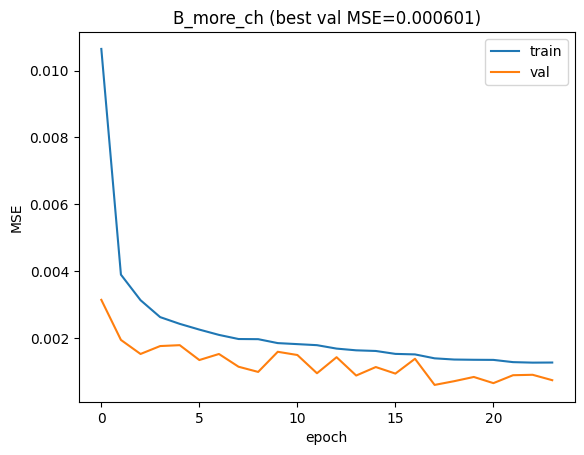

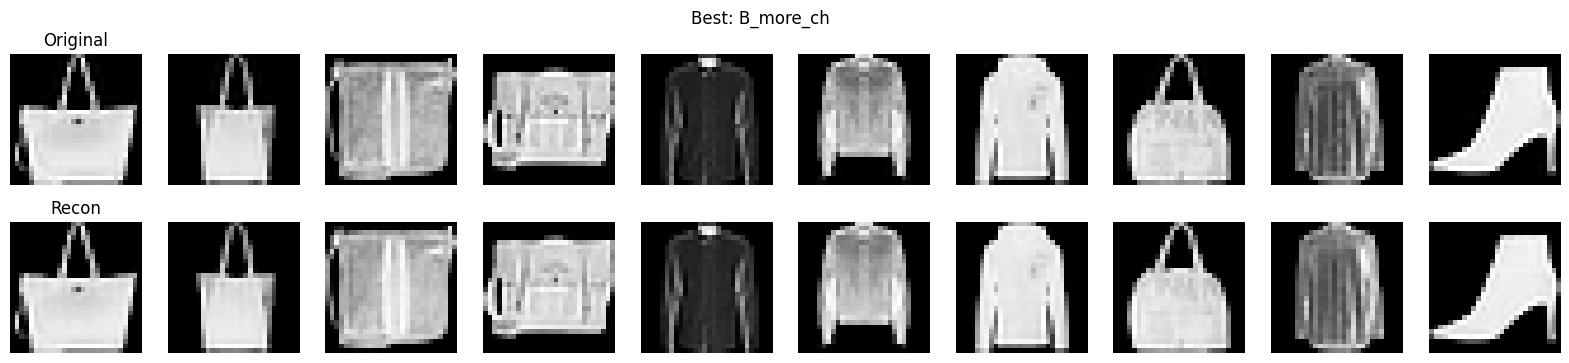

In [ ]:
best_cfg, best_model, best_hist, best_val = best
print("Mejor experimento:", best_cfg["name"], "val MSE:", best_val)

plot_history(best_hist, title=f"{best_cfg['name']} (best val MSE={best_val:.6f})")

train_loader, val_loader = make_loaders(best_cfg["batch_size"])
show_reconstructions(best_model, val_loader, n=10, title=f"Best: {best_cfg['name']}")

In [ ]:
###2

In [ ]:
# =============================================================================
# Clasificador CNN profundo con pre-entrenamiento (encoder congelado)
# Fashion-MNIST + LogSoftMax + NLLLoss + accuracy train/val
# =============================================================================

import torch
import torch.nn as nn
import numpy as np
from tqdm import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# 1) Utilidades
# ---------------------------------------------------------
def set_requires_grad(module: nn.Module, flag: bool):
    for p in module.parameters():
        p.requires_grad = flag

@torch.no_grad()
def accuracy_from_logprobs(logp: torch.Tensor, y: torch.Tensor) -> float:
    return (logp.argmax(dim=1) == y).float().mean().item()

@torch.no_grad()
def evaluate_classifier(model, loader):
    """Devuelve (loss_promedio, acc_promedio)"""
    model.eval()
    criterion = nn.NLLLoss()
    losses, accs = [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logp = model(x)
        loss = criterion(logp, y)
        losses.append(loss.item())
        accs.append(accuracy_from_logprobs(logp, y))
    return float(np.mean(losses)), float(np.mean(accs))


# ---------------------------------------------------------
# 2) Definir el clasificador: encoder (pre-entrenado) + head conv profundo
#    IMPORTANTE: la salida del encoder es la entrada del head.
# ---------------------------------------------------------
class ConvClassifier(nn.Module):
    """
    ConvClassifier( encoder_preentrenado_congelado + head_conv_profundo )
    - La salida final aplica LogSoftmax(dim=1)
    - La pérdida se calcula con NLLLoss (equivalente a CE con LogSoftmax)
    """
    def __init__(self, encoder: nn.Module, num_classes: int = 10, dropout_p: float = 0.35):
        super().__init__()
        self.encoder = encoder

        # Asumimos encoder tipo: (B, 256, 2, 2) si usaste el ConvEncoder del AE que te pasé.
        # Si tu encoder tiene otra forma, esta head igual suele funcionar porque usa AdaptiveAvgPool2d.
        self.head = nn.Sequential(
            nn.Conv2d(256, 384, kernel_size=3, padding=1),
            nn.BatchNorm2d(384),
            nn.GELU(),
            nn.Dropout2d(dropout_p),

            nn.Conv2d(384, 384, kernel_size=3, padding=1),
            nn.BatchNorm2d(384),
            nn.GELU(),
            nn.Dropout2d(dropout_p),

            nn.Conv2d(384, 256, kernel_size=1),
            nn.BatchNorm2d(256),
            nn.GELU(),

            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),

            nn.Linear(256, 128),
            nn.GELU(),
            nn.Dropout(dropout_p),

            nn.Linear(128, num_classes),
            nn.LogSoftmax(dim=1)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.head(z)


# ---------------------------------------------------------
# 3) Construir el modelo usando el encoder del autoencoder ya entrenado (ae.encoder)
#    y congelarlo
# ---------------------------------------------------------
# Requiere que ya exista "ae" entrenado y que tenga atributo "encoder"
# (ej: ae = ConvAutoencoder(...); ae, _ = train_autoencoder(...))

encoder_pretrained = ae.encoder
encoder_pretrained.to(DEVICE)
set_requires_grad(encoder_pretrained, False)  # 🔒 congelado

model = ConvClassifier(encoder_pretrained, num_classes=10, dropout_p=0.35).to(DEVICE)


# ---------------------------------------------------------
# 4) Entrenamiento del clasificador (solo head)
#    - LogSoftmax + NLLLoss
#    - accuracy train/val por época
#    - guardar mejor época por val_loss (o val_acc)
#    - detectar "época donde deja de mejorar": la mejor por val_loss/val_acc
# ---------------------------------------------------------
def train_pretrained_frozen_classifier(
    model: nn.Module,
    train_loader,
    val_loader,
    epochs: int = 20,
    lr: float = 1e-3,
    weight_decay: float = 5e-4,
    optimizer_name: str = "RMSprop",
    clip_grad: float = 2.0,
    early_stop_patience: int = 5,
):
    """
    Entrena SOLO el head (encoder congelado).
    Devuelve:
      - model con mejores pesos (según val_loss)
      - history con curvas
      - best_epoch (época donde generalización fue mejor)
    """
    # Confirmación: encoder congelado
    assert all([p.requires_grad is False for p in model.encoder.parameters()]), \
        "El encoder NO está congelado. Asegurate de set_requires_grad(encoder, False)."

    criterion = nn.NLLLoss()

    # Optimiza solo parámetros entrenables (head)
    params = [p for p in model.parameters() if p.requires_grad]

    if optimizer_name.lower() == "adamw":
        optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    elif optimizer_name.lower() == "sgd":
        optimizer = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay, nesterov=True)
    else:
        # RMSprop (suele andar bien en CNNs)
        optimizer = torch.optim.RMSprop(params, lr=lr, momentum=0.9, weight_decay=weight_decay)

    # Scheduler: reduce LR si val_loss no mejora
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [],  "val_acc": [],
        "lr": []
    }

    best_val = float("inf")
    best_state = None
    best_epoch = 0
    epochs_no_improve = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses, train_accs = [], []

        pbar = tqdm(train_loader, desc=f"[CLS frozen] Epoch {epoch}/{epochs}", leave=False)
        for x, y in pbar:
            x, y = x.to(DEVICE), y.to(DEVICE)

            optimizer.zero_grad()
            logp = model(x)                 # LogSoftmax salida
            loss = criterion(logp, y)        # NLLLoss

            loss.backward()
            if clip_grad is not None:
                nn.utils.clip_grad_norm_(params, max_norm=clip_grad)
            optimizer.step()

            acc = accuracy_from_logprobs(logp.detach(), y)
            train_losses.append(loss.item())
            train_accs.append(acc)

            pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{acc:.3f}")

        # Validación
        val_loss, val_acc = evaluate_classifier(model, val_loader)

        train_loss = float(np.mean(train_losses))
        train_acc = float(np.mean(train_accs))
        current_lr = float(optimizer.param_groups[0]["lr"])

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["lr"].append(current_lr)

        scheduler.step(val_loss)

        print(
            f"[CLS frozen] epoch={epoch:02d} "
            f"train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
            f"train_acc={train_acc:.3f} val_acc={val_acc:.3f} lr={current_lr:.2e}"
        )

        # Guardar mejor por val_loss (generalización)
        if val_loss < best_val:
            best_val = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        # Early stopping opcional
        if early_stop_patience is not None and epochs_no_improve >= early_stop_patience:
            print(f"Early stopping: {epochs_no_improve} épocas sin mejora en val_loss.")
            break

    # Cargar mejor estado
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, best_epoch


# ---------------------------------------------------------
# 5) Correr entrenamiento (ajustá hiperparámetros acá)
# ---------------------------------------------------------
EPOCHS_CLS = 25

model, hist, best_epoch = train_pretrained_frozen_classifier(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS_CLS,
    lr=1e-3,                 # tasa de aprendizaje del head
    weight_decay=5e-4,
    optimizer_name="RMSprop", # probá "AdamW" también
    clip_grad=2.0,
    early_stop_patience=6
)

print(f"\n✅ Mejor época (según val_loss): {best_epoch}")


# ---------------------------------------------------------
# 6) Evaluación final en test
# ---------------------------------------------------------
test_loss, test_acc = evaluate_classifier(model, test_loader)
print(f"[TEST] loss={test_loss:.4f} acc={test_acc:.3f}")


# ---------------------------------------------------------
# 7) (Opcional) Gráficos train/val para detectar desde qué época deja de mejorar
#     solo matplotlib (como pedías)
# ---------------------------------------------------------
import matplotlib.pyplot as plt

epochs_ran = len(hist["train_loss"])
x = np.arange(1, epochs_ran + 1)

fig, ax = plt.subplots(figsize=(8,4))
ax.plot(x, hist["train_loss"], label="train_loss")
ax.plot(x, hist["val_loss"], label="val_loss")
ax.axvline(best_epoch, linestyle="--", label=f"best_epoch={best_epoch}")
ax.set_title("Clasificador (encoder congelado) - Pérdida")
ax.set_xlabel("Época")
ax.set_ylabel("NLLLoss")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8,4))
ax.plot(x, hist["train_acc"], label="train_acc")
ax.plot(x, hist["val_acc"], label="val_acc")
ax.axvline(best_epoch, linestyle="--", label=f"best_epoch={best_epoch}")
ax.set_title("Clasificador (encoder congelado) - Accuracy")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.legend()
plt.tight_layout()
plt.show()

NameError: name 'ae' is not defined